In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

In [ ]:
from google.colab import files

uploaded = files.upload()
file_path = list(uploaded.keys())[0]

print("File loaded:", file_path)

Saving Supplier Quality Analysis.xlsx to Supplier Quality Analysis (2).xlsx
File loaded: Supplier Quality Analysis (2).xlsx


In [ ]:
xls = pd.ExcelFile(file_path)

print("Workbook sheets:")
for sheet in xls.sheet_names:
    print("-", sheet)

Workbook sheets:
- Metrics
- Category
- Date
- Defect
- Defect Type
- Material Type
- Plant
- Vendor


In [ ]:
metrics = pd.read_excel(file_path, sheet_name="Metrics")
category = pd.read_excel(file_path, sheet_name="Category")
date_dim = pd.read_excel(file_path, sheet_name="Date")
defect = pd.read_excel(file_path, sheet_name="Defect")
defect_type = pd.read_excel(file_path, sheet_name="Defect Type")
material_type = pd.read_excel(file_path, sheet_name="Material Type")
plant = pd.read_excel(file_path, sheet_name="Plant")
vendor = pd.read_excel(file_path, sheet_name="Vendor")

tables = {
    "Metrics": metrics,
    "Category": category,
    "Date": date_dim,
    "Defect": defect,
    "Defect Type": defect_type,
    "Material Type": material_type,
    "Plant": plant,
    "Vendor": vendor
}

for name, table in tables.items():
    print(f"{name:15} -> {table.shape}")

Metrics         -> (6145, 10)
Category        -> (6, 3)
Date            -> (1096, 5)
Defect          -> (305, 2)
Defect Type     -> (3, 3)
Material Type   -> (22, 2)
Plant           -> (24, 2)
Vendor          -> (328, 2)


In [ ]:
display(metrics.head())

print("\nMetrics shape:", metrics.shape)

print("\nMetrics columns:")
print(metrics.columns.tolist())

,Date,Sub Category ID,Plant ID,Vendor ID,Material ID,Defect Type ID,Material Type ID,Defect ID,Defect Qty,Downtime min
0,41974,6,10,173,959,1,9,247,0,0
1,41962,6,10,162,2056,1,9,247,0,0
2,41961,6,10,129,1778,1,9,247,0,0
3,41960,6,10,69,2045,1,9,247,0,0
4,41960,6,10,69,2046,1,9,247,0,0



Metrics shape: (6145, 10)

Metrics columns:
['Date', 'Sub Category ID', 'Plant ID', 'Vendor ID', 'Material ID', 'Defect Type ID', 'Material Type ID', 'Defect ID', 'Defect Qty', 'Downtime min']


In [ ]:
missing_summary = pd.DataFrame({
    "Missing_count": metrics.isna().sum(),
    "Missing_percent": metrics.isna().mean() * 100
})

display(missing_summary)

,Missing_count,Missing_percent
Date,0,0.00
Sub Category ID,0,0.00
Plant ID,0,0.00
Vendor ID,0,0.00
Material ID,0,0.00
Defect Type ID,0,0.00
Material Type ID,0,0.00
Defect ID,0,0.00
Defect Qty,0,0.00
Downtime min,0,0.00


In [ ]:
for name, table in tables.items():
    print("\n" + "=" * 50)
    print(name)
    print(table.isna().sum())


Metrics
Date                0
Sub Category ID     0
Plant ID            0
Vendor ID           0
Material ID         0
Defect Type ID      0
Material Type ID    0
Defect ID           0
Defect Qty          0
Downtime min        0
dtype: int64

Category
Sub Category       0
Sub Category ID    0
Category           0
dtype: int64

Date
Year           0
MonthNumber    0
Week           0
Date           0
Month          0
dtype: int64

Defect
Defect       0
Defect ID    0
dtype: int64

Defect Type
Defect Type       0
Defect Type ID    0
Sort              0
dtype: int64

Material Type
Material Type       0
Material Type ID    0
dtype: int64

Plant
Plant       0
Plant ID    0
dtype: int64

Vendor
Vendor       0
Vendor ID    0
dtype: int64


In [ ]:
duplicate_extra = metrics.duplicated().sum()
duplicate_all = metrics.duplicated(keep=False).sum()

duplicate_groups = (
    metrics[
        metrics.duplicated(keep=False)
    ]
    .groupby(
        metrics.columns.tolist(),
        dropna=False
    )
    .size()
    .reset_index(name="Frequency")
)

print("Duplicate rows beyond first occurrence:", duplicate_extra)
print("All rows involved in duplicate groups:", duplicate_all)
print("Number of duplicate groups:", len(duplicate_groups))

if len(duplicate_groups) > 0:
    print(
        "Largest duplicate group:",
        duplicate_groups["Frequency"].max()
    )

display(
    duplicate_groups
    .sort_values("Frequency", ascending=False)
    .head(20)
)

Duplicate rows beyond first occurrence: 193
All rows involved in duplicate groups: 326
Number of duplicate groups: 133
Largest duplicate group: 7


,Date,Sub Category ID,Plant ID,Vendor ID,Material ID,Defect Type ID,Material Type ID,Defect ID,Defect Qty,Downtime min,Frequency
14,41370,2,13,2,50,1,8,37,0,0,7
42,41614,2,13,2,50,1,8,37,0,0,7
103,41913,3,4,17,608,1,13,275,0,0,6
99,41906,4,12,4,60,3,2,46,4237,15,6
46,41632,4,5,57,228,1,9,69,0,0,5
35,41586,3,4,17,608,1,13,100,0,0,5
66,41790,3,4,17,608,1,13,275,0,0,5
18,41388,4,5,57,228,1,9,69,0,0,5
7,41341,3,4,17,608,1,13,100,0,0,5
131,41988,3,4,17,608,1,13,289,0,0,4


In [ ]:
dimension_keys = {
    "Vendor": (vendor, "Vendor ID"),
    "Plant": (plant, "Plant ID"),
    "Defect": (defect, "Defect ID"),
    "Defect Type": (defect_type, "Defect Type ID"),
    "Material Type": (material_type, "Material Type ID"),
    "Category": (category, "Sub Category ID")
}

key_audit = []

for name, (table, key) in dimension_keys.items():
    key_audit.append({
        "Table": name,
        "Key": key,
        "Rows": len(table),
        "Unique_keys": table[key].nunique(),
        "Duplicate_keys": table[key].duplicated().sum(),
        "Missing_keys": table[key].isna().sum()
    })

key_audit = pd.DataFrame(key_audit)

display(key_audit)

,Table,Key,Rows,Unique_keys,Duplicate_keys,Missing_keys
0,Vendor,Vendor ID,328,328,0,0
1,Plant,Plant ID,24,24,0,0
2,Defect,Defect ID,305,305,0,0
3,Defect Type,Defect Type ID,3,3,0,0
4,Material Type,Material Type ID,22,22,0,0
5,Category,Sub Category ID,6,6,0,0


In [ ]:
def convert_excel_date(series):
    if pd.api.types.is_numeric_dtype(series):
        return pd.to_datetime(
            series,
            unit="D",
            origin="1899-12-30"
        )
    else:
        return pd.to_datetime(series)

metrics["Date"] = convert_excel_date(metrics["Date"])
date_dim["Date"] = convert_excel_date(date_dim["Date"])

print("Metrics start date:", metrics["Date"].min())
print("Metrics end date:", metrics["Date"].max())

print("Date dimension start:", date_dim["Date"].min())
print("Date dimension end:", date_dim["Date"].max())

Metrics start date: 2013-01-01 00:00:00
Metrics end date: 2014-12-31 00:00:00
Date dimension start: 2012-01-01 00:00:00
Date dimension end: 2014-12-31 00:00:00


In [ ]:
print("Date dimension rows:", len(date_dim))
print("Unique dates:", date_dim["Date"].nunique())
print(
    "Duplicate dates:",
    date_dim["Date"].duplicated().sum()
)
print(
    "Missing dates:",
    date_dim["Date"].isna().sum()
)

Date dimension rows: 1096
Unique dates: 1096
Duplicate dates: 0
Missing dates: 0


In [ ]:
numeric_cols = [
    "Defect Qty",
    "Downtime min"
]

display(
    metrics[numeric_cols].describe()
)

for col in numeric_cols:

    print(
        f"{col} negative values:",
        (metrics[col] < 0).sum()
    )

    print(
        f"{col} zero values:",
        (metrics[col] == 0).sum()
    )

    print()

,Defect Qty,Downtime min
count,"6,145.00","6,145.00"
mean,"9,114.88",22.67
std,"30,583.83",75.37
min,0.00,0.00
25%,6.00,0.00
50%,438.00,0.00
75%,"5,127.00",20.00
max,"487,008.00",999.00


Defect Qty negative values: 0
Defect Qty zero values: 1240

Downtime min negative values: 0
Downtime min zero values: 3957



In [ ]:
join_keys = [
    ("Vendor ID", metrics, vendor),
    ("Plant ID", metrics, plant),
    ("Defect ID", metrics, defect),
    ("Defect Type ID", metrics, defect_type),
    ("Material Type ID", metrics, material_type),
    ("Sub Category ID", metrics, category)
]

for key, fact, dim in join_keys:

    fact_ids = set(fact[key].dropna())
    dim_ids = set(dim[key].dropna())

    orphan_ids = fact_ids - dim_ids

    print(
        f"{key:20} | "
        f"Fact unique: {len(fact_ids):4} | "
        f"Dimension unique: {len(dim_ids):4} | "
        f"Orphan IDs: {len(orphan_ids)}"
    )

orphan_dates = (
    set(metrics["Date"].dropna())
    - set(date_dim["Date"].dropna())
)

print("\nOrphan dates:", len(orphan_dates))

Vendor ID            | Fact unique:  320 | Dimension unique:  328 | Orphan IDs: 0
Plant ID             | Fact unique:   24 | Dimension unique:   24 | Orphan IDs: 0
Defect ID            | Fact unique:  300 | Dimension unique:  305 | Orphan IDs: 0
Defect Type ID       | Fact unique:    3 | Dimension unique:    3 | Orphan IDs: 0
Material Type ID     | Fact unique:   22 | Dimension unique:   22 | Orphan IDs: 0
Sub Category ID      | Fact unique:    6 | Dimension unique:    6 | Orphan IDs: 0

Orphan dates: 0


In [ ]:
df = metrics.copy()

df = df.merge(
    vendor,
    on="Vendor ID",
    how="left",
    validate="m:1"
)

df = df.merge(
    plant,
    on="Plant ID",
    how="left",
    validate="m:1"
)

df = df.merge(
    date_dim,
    on="Date",
    how="left",
    validate="m:1"
)

df = df.merge(
    defect,
    on="Defect ID",
    how="left",
    validate="m:1"
)

df = df.merge(
    defect_type,
    on="Defect Type ID",
    how="left",
    validate="m:1"
)

df = df.merge(
    material_type,
    on="Material Type ID",
    how="left",
    validate="m:1"
)

df = df.merge(
    category,
    on="Sub Category ID",
    how="left",
    validate="m:1"
)

df["Year"] = pd.to_numeric(
    df["Year"],
    errors="coerce"
).astype("Int64")

print("Original fact rows:", len(metrics))
print("Rows after join:", len(df))
print("Columns after join:", df.shape[1])

assert len(df) == len(metrics)

print("PASS: fact-table row count preserved.")

Original fact rows: 6145
Rows after join: 6145
Columns after join: 22
PASS: fact-table row count preserved.


In [ ]:
join_check = pd.DataFrame({
    "Variable": [
        "Vendor",
        "Plant",
        "Defect",
        "Defect Type",
        "Material Type",
        "Sub Category"
    ],

    "Missing_after_join": [
        df["Vendor"].isna().sum(),
        df["Plant"].isna().sum(),
        df["Defect"].isna().sum(),
        df["Defect Type"].isna().sum(),
        df["Material Type"].isna().sum(),
        df["Sub Category"].isna().sum()
    ]
})

display(join_check)

,Variable,Missing_after_join
0,Vendor,0
1,Plant,0
2,Defect,0
3,Defect Type,0
4,Material Type,0
5,Sub Category,0


In [ ]:
cleaning_log = pd.DataFrame([
    {
        "Rule":
        "Converted Metrics Date from Excel serial number to datetime",

        "Rows affected":
        len(metrics),

        "Justification":
        "Required for correct time-based analysis"
    },

    {
        "Rule":
        "Converted Date dimension Date from Excel serial number to datetime",

        "Rows affected":
        len(date_dim),

        "Justification":
        "Required for reliable fact-dimension joining"
    },

    {
        "Rule":
        "Validated dimension keys and joined fact table to required dimensions",

        "Rows affected":
        len(df),

        "Justification":
        "All joins were many-to-one and preserved the original fact-table row count"
    },

    {
        "Rule":
        "Retained exact duplicate observations",

        "Rows affected":
        duplicate_extra,

        "Justification":
        "No event-level unique identifier exists, so identical records cannot be confirmed as erroneous duplicates"
    }
])

display(cleaning_log)

,Rule,Rows affected,Justification
0,Converted Metrics Date from Excel serial numbe...,6145,Required for correct time-based analysis
1,Converted Date dimension Date from Excel seria...,1096,Required for reliable fact-dimension joining
2,Validated dimension keys and joined fact table...,6145,All joins were many-to-one and preserved the o...
3,Retained exact duplicate observations,193,"No event-level unique identifier exists, so id..."


In [ ]:
data_dictionary = pd.DataFrame([
    {
        "Variable": "Date",
        "Definition": "Date associated with the supplier-quality record",
        "Unit": "Date",
        "Source": "Metrics / Date"
    },

    {
        "Variable": "Vendor",
        "Definition": "Anonymised supplier name",
        "Unit": "Category",
        "Source": "Vendor"
    },

    {
        "Variable": "Plant",
        "Definition": "Manufacturing plant associated with the record",
        "Unit": "Category",
        "Source": "Plant"
    },

    {
        "Variable": "Defect Qty",
        "Definition": "Recorded quantity of defective material",
        "Unit": "Units",
        "Source": "Metrics"
    },

    {
        "Variable": "Downtime min",
        "Definition": "Recorded production downtime associated with the supplier-quality record",
        "Unit": "Minutes",
        "Source": "Metrics"
    },

    {
        "Variable": "Defect Type",
        "Definition": "Classification of defect impact",
        "Unit": "Category",
        "Source": "Defect Type"
    },

    {
        "Variable": "Material Type",
        "Definition": "Material category associated with the record",
        "Unit": "Category",
        "Source": "Material Type"
    }
])

display(data_dictionary)

,Variable,Definition,Unit,Source
0,Date,Date associated with the supplier-quality record,Date,Metrics / Date
1,Vendor,Anonymised supplier name,Category,Vendor
2,Plant,Manufacturing plant associated with the record,Category,Plant
3,Defect Qty,Recorded quantity of defective material,Units,Metrics
4,Downtime min,Recorded production downtime associated with t...,Minutes,Metrics
5,Defect Type,Classification of defect impact,Category,Defect Type
6,Material Type,Material category associated with the record,Category,Material Type


In [ ]:
dataset_summary = pd.Series({
    "Observations": len(df),
    "Unique vendors": df["Vendor"].nunique(),
    "Plants": df["Plant"].nunique(),
    "Start date": df["Date"].min(),
    "End date": df["Date"].max(),
    "Total defect quantity": df["Defect Qty"].sum(),
    "Total downtime minutes": df["Downtime min"].sum()
})

display(dataset_summary)

,0
Observations,6145
Unique vendors,318
Plants,24
Start date,2013-01-01 00:00:00
End date,2014-12-31 00:00:00
Total defect quantity,56010955
Total downtime minutes,139288


In [ ]:
year_summary = (
    df.groupby("Year")
    .agg(
        observations=("Downtime min", "size"),
        total_downtime=("Downtime min", "sum"),
        total_defects=("Defect Qty", "sum"),
        vendors=("Vendor", "nunique")
    )
    .reset_index()
)

display(year_summary)

,Year,observations,total_downtime,total_defects,vendors
0,2013,2757,62681,23027902,162
1,2014,3388,76607,32983053,287


In [ ]:
downtime_2013 = year_summary.loc[
    year_summary["Year"] == 2013,
    "total_downtime"
].iloc[0]

downtime_2014 = year_summary.loc[
    year_summary["Year"] == 2014,
    "total_downtime"
].iloc[0]

absolute_change = (
    downtime_2014
    - downtime_2013
)

percent_change = (
    absolute_change
    / downtime_2013
    * 100
)

print("2013 downtime:", f"{downtime_2013:,.0f}")
print("2014 downtime:", f"{downtime_2014:,.0f}")
print("Absolute change:", f"{absolute_change:,.0f}")
print("Percent change:", f"{percent_change:.2f}%")

2013 downtime: 62,681
2014 downtime: 76,607
Absolute change: 13,926
Percent change: 22.22%


In [ ]:
vendor_year = (
    df.groupby(
        ["Vendor", "Year"],
        as_index=False
    )
    .agg(
        Downtime_min=("Downtime min", "sum")
    )
)

display(
    vendor_year
    .sort_values(
        "Downtime_min",
        ascending=False
    )
    .head(20)
)

,Vendor,Year,Downtime_min
228,Reddoit,2013,15319
229,Reddoit,2014,10866
212,Plustax,2014,5795
243,Sanlab,2014,5655
440,xx-way,2013,5082
441,xx-way,2014,4924
242,Sanlab,2013,4620
211,Plustax,2013,4610
219,Quotelane,2014,4185
422,scotquote,2014,3643


In [ ]:
vendors_2013 = set(
    df.loc[
        df["Year"] == 2013,
        "Vendor"
    ]
    .dropna()
    .unique()
)

vendors_2014 = set(
    df.loc[
        df["Year"] == 2014,
        "Vendor"
    ]
    .dropna()
    .unique()
)

common_vendors = vendors_2013 & vendors_2014
only_2013 = vendors_2013 - vendors_2014
only_2014 = vendors_2014 - vendors_2013

print("Vendors in 2013:", len(vendors_2013))
print("Vendors in 2014:", len(vendors_2014))
print("Vendors in both years:", len(common_vendors))
print("Only in 2013:", len(only_2013))
print("Only in 2014:", len(only_2014))

Vendors in 2013: 162
Vendors in 2014: 287
Vendors in both years: 131
Only in 2013: 31
Only in 2014: 156


In [ ]:
vendor_compare = (
    vendor_year
    .pivot(
        index="Vendor",
        columns="Year",
        values="Downtime_min"
    )
    .reset_index()
)

vendor_compare.columns.name = None

vendor_compare = vendor_compare.rename(
    columns={
        2013: "Downtime_2013",
        2014: "Downtime_2014"
    }
)

vendor_compare["Vendor_status"] = np.select(
    [
        vendor_compare["Downtime_2013"].notna()
        & vendor_compare["Downtime_2014"].notna(),

        vendor_compare["Downtime_2013"].notna()
        & vendor_compare["Downtime_2014"].isna(),

        vendor_compare["Downtime_2013"].isna()
        & vendor_compare["Downtime_2014"].notna()
    ],
    [
        "Both years",
        "2013 only",
        "2014 only"
    ],
    default="Unknown"
)

display(
    vendor_compare["Vendor_status"]
    .value_counts()
)

,count
Vendor_status,
2014 only,156
Both years,131
2013 only,31


In [ ]:
common_compare = (
    vendor_compare[
        vendor_compare["Vendor_status"] == "Both years"
    ]
    .copy()
    .reset_index(drop=True)
)

common_compare["Absolute_change"] = (
    common_compare["Downtime_2014"]
    - common_compare["Downtime_2013"]
)

common_compare["Pct_change"] = np.where(
    common_compare["Downtime_2013"] > 0,

    (
        common_compare["Absolute_change"]
        / common_compare["Downtime_2013"]
        * 100
    ),

    np.nan
)

print("Common vendors:", len(common_compare))

Common vendors: 131


In [ ]:
top_2014_all = (
    vendor_year[
        vendor_year["Year"] == 2014
    ]
    .sort_values(
        "Downtime_min",
        ascending=False
    )
    .head(15)
    .reset_index(drop=True)
)

display(top_2014_all)

,Vendor,Year,Downtime_min
0,Reddoit,2014,10866
1,Plustax,2014,5795
2,Sanlab,2014,5655
3,xx-way,2014,4924
4,Quotelane,2014,4185
5,scotquote,2014,3643
6,J-lax,2014,3018
7,Planethouse,2014,2984
8,Sanin,2014,2854
9,xx-bam,2014,2745


In [ ]:
top_current_common = (
    common_compare
    .sort_values(
        "Downtime_2014",
        ascending=False
    )
    .head(15)
    .reset_index(drop=True)
)

display(
    top_current_common[
        [
            "Vendor",
            "Downtime_2013",
            "Downtime_2014",
            "Absolute_change",
            "Pct_change"
        ]
    ]
)

,Vendor,Downtime_2013,Downtime_2014,Absolute_change,Pct_change
0,Reddoit,"15,319.00","10,866.00","-4,453.00",-29.07
1,Plustax,"4,610.00","5,795.00","1,185.00",25.70
2,Sanlab,"4,620.00","5,655.00","1,035.00",22.40
3,xx-way,"5,082.00","4,924.00",-158.00,-3.11
4,Quotelane,"1,793.00","4,185.00","2,392.00",133.41
5,scotquote,"1,322.00","3,643.00","2,321.00",175.57
6,J-lax,300.00,"3,018.00","2,718.00",906.00
7,Planethouse,398.00,"2,984.00","2,586.00",649.75
8,Sanin,804.00,"2,854.00","2,050.00",254.98
9,xx-bam,860.00,"2,745.00","1,885.00",219.19


In [ ]:
top_increase_common = (
    common_compare
    .sort_values(
        "Absolute_change",
        ascending=False
    )
    .head(15)
    .reset_index(drop=True)
)

display(
    top_increase_common[
        [
            "Vendor",
            "Downtime_2013",
            "Downtime_2014",
            "Absolute_change",
            "Pct_change"
        ]
    ]
)

,Vendor,Downtime_2013,Downtime_2014,Absolute_change,Pct_change
0,J-lax,300.00,"3,018.00","2,718.00",906.00
1,Planethouse,398.00,"2,984.00","2,586.00",649.75
2,Quotelane,"1,793.00","4,185.00","2,392.00",133.41
3,scotquote,"1,322.00","3,643.00","2,321.00",175.57
4,Sanin,804.00,"2,854.00","2,050.00",254.98
5,xx-bam,860.00,"2,745.00","1,885.00",219.19
6,Keyzunbase,155.00,"1,889.00","1,734.00","1,118.71"
7,Damdexon,32.00,"1,387.00","1,355.00","4,234.38"
8,Singleholdings,0.00,"1,299.00","1,299.00",NaN
9,Plustax,"4,610.00","5,795.00","1,185.00",25.70


In [ ]:
top_decrease_common = (
    common_compare
    .sort_values(
        "Absolute_change",
        ascending=True
    )
    .head(15)
    .reset_index(drop=True)
)

display(
    top_decrease_common[
        [
            "Vendor",
            "Downtime_2013",
            "Downtime_2014",
            "Absolute_change",
            "Pct_change"
        ]
    ]
)

,Vendor,Downtime_2013,Downtime_2014,Absolute_change,Pct_change
0,Reddoit,"15,319.00","10,866.00","-4,453.00",-29.07
1,Scotfase,"2,118.00",0.00,"-2,118.00",-100.00
2,Funlax,"1,998.00",0.00,"-1,998.00",-100.00
3,Fax-ex,"1,982.00",181.00,"-1,801.00",-90.87
4,Subdrill,"1,865.00",356.00,"-1,509.00",-80.91
5,ontotam,"2,330.00",997.00,"-1,333.00",-57.21
6,Silverfase,"1,280.00",0.00,"-1,280.00",-100.00
7,Instrip,"2,094.00",994.00,"-1,100.00",-52.53
8,Viatom,720.00,0.00,-720.00,-100.00
9,Dentocity,"1,884.00","1,204.00",-680.00,-36.09


In [ ]:
common_df = df[
    df["Vendor"].isin(common_vendors)
].copy()

common_year_summary = (
    common_df
    .groupby("Year")
    .agg(
        observations=("Downtime min", "size"),
        total_downtime=("Downtime min", "sum"),
        total_defects=("Defect Qty", "sum"),
        vendors=("Vendor", "nunique")
    )
    .reset_index()
)

display(common_year_summary)

common_2013 = (
    common_year_summary.loc[
        common_year_summary["Year"] == 2013,
        "total_downtime"
    ]
    .iloc[0]
)

common_2014 = (
    common_year_summary.loc[
        common_year_summary["Year"] == 2014,
        "total_downtime"
    ]
    .iloc[0]
)

common_absolute_change = (
    common_2014
    - common_2013
)

common_pct_change = (
    common_absolute_change
    / common_2013
    * 100
)

print("\nCOMMON VENDORS ONLY")
print("2013:", f"{common_2013:,.0f}")
print("2014:", f"{common_2014:,.0f}")
print(
    "Absolute change:",
    f"{common_absolute_change:,.0f}"
)
print(
    "Percent change:",
    f"{common_pct_change:.2f}%"
)

,Year,observations,total_downtime,total_defects,vendors
0,2013,2672,61446,22337754,131
1,2014,2955,69939,26894602,131



COMMON VENDORS ONLY
2013: 61,446
2014: 69,939
Absolute change: 8,493
Percent change: 13.82%


In [ ]:
comparison_summary = pd.DataFrame({
    "Comparison": [
        "All recorded vendors",
        f"{len(common_vendors)} common vendors"
    ],

    "Downtime_2013": [
        downtime_2013,
        common_2013
    ],

    "Downtime_2014": [
        downtime_2014,
        common_2014
    ],

    "Absolute_change": [
        absolute_change,
        common_absolute_change
    ],

    "Pct_change": [
        percent_change,
        common_pct_change
    ]
})

display(comparison_summary)

,Comparison,Downtime_2013,Downtime_2014,Absolute_change,Pct_change
0,All recorded vendors,62681,76607,13926,22.22
1,131 common vendors,61446,69939,8493,13.82


In [ ]:
plant_summary = (
    df.groupby(
        ["Plant", "Year"]
    )
    .agg(
        total_downtime=("Downtime min", "sum"),
        total_defects=("Defect Qty", "sum"),
        observations=("Downtime min", "size")
    )
    .reset_index()
)

display(
    plant_summary
    .sort_values(
        "total_downtime",
        ascending=False
    )
    .head(20)
)

,Plant,Year,total_downtime,total_defects,observations
43,"Springfield, IL",2013,10963,3570027,232
42,"Skokie, IL",2014,8442,1510634,89
3,"Bangor, MI",2014,8401,1562082,198
7,Cincinnati OH,2014,8338,532894,191
33,"Monon, IN",2013,7179,1900315,177
12,"Detriot, MI",2014,6996,4590115,237
6,Cincinnati OH,2013,6527,678424,128
21,"Indianapolis, IN",2013,6447,773751,448
44,"Springfield, IL",2014,6348,216542,154
38,"Northbrook, IL",2014,5009,2432393,138


In [ ]:
material_summary = (
    df.groupby(
        ["Material Type", "Year"]
    )
    .agg(
        total_downtime=("Downtime min", "sum"),
        total_defects=("Defect Qty", "sum"),
        observations=("Downtime min", "size")
    )
    .reset_index()
)

display(
    material_summary
    .sort_values(
        "total_downtime",
        ascending=False
    )
    .head(20)
)

,Material Type,Year,total_downtime,total_defects,observations
8,Corrugate,2013,26728,1331476,780
9,Corrugate,2014,26308,879758,735
35,Raw Materials,2014,13229,11210703,1181
34,Raw Materials,2013,10699,3335388,665
2,Carton,2013,7582,4493635,200
16,Film,2014,6473,4715924,332
3,Carton,2014,5287,3433064,202
1,Batteries,2014,5024,370854,174
7,Controllers,2014,4923,1212108,141
14,Electrolytes,2014,4166,1815793,81


In [ ]:
defect_type_summary = (
    df.groupby(
        ["Defect Type", "Year"]
    )
    .agg(
        total_downtime=("Downtime min", "sum"),
        total_defects=("Defect Qty", "sum"),
        observations=("Downtime min", "size")
    )
    .reset_index()
)

display(defect_type_summary)

,Defect Type,Year,total_downtime,total_defects,observations
0,Impact,2013,53628,10776021,947
1,Impact,2014,52006,8619548,990
2,No Impact,2013,3641,5170693,1115
3,No Impact,2014,1498,11437875,1416
4,Rejected,2013,5412,7081188,695
5,Rejected,2014,23103,12925630,982


In [ ]:
defect_type_compare = (
    defect_type_summary
    .pivot(
        index="Defect Type",
        columns="Year",
        values="total_downtime"
    )
    .reset_index()
)

defect_type_compare.columns.name = None

defect_type_compare = defect_type_compare.rename(
    columns={
        2013: "Downtime_2013",
        2014: "Downtime_2014"
    }
)

defect_type_compare["Absolute_change"] = (
    defect_type_compare["Downtime_2014"]
    - defect_type_compare["Downtime_2013"]
)

defect_type_compare["Pct_change"] = (
    defect_type_compare["Absolute_change"]
    / defect_type_compare["Downtime_2013"]
    * 100
)

display(defect_type_compare)

,Defect Type,Downtime_2013,Downtime_2014,Absolute_change,Pct_change
0,Impact,53628,52006,-1622,-3.02
1,No Impact,3641,1498,-2143,-58.86
2,Rejected,5412,23103,17691,326.88


In [ ]:
vendor_metrics_2014 = (
    df[
        df["Year"] == 2014
    ]
    .groupby("Vendor")
    .agg(
        total_downtime=("Downtime min", "sum"),
        total_defects=("Defect Qty", "sum"),
        observations=("Downtime min", "size")
    )
    .reset_index()
)

vendor_metrics_2014["Downtime_rank"] = (
    vendor_metrics_2014["total_downtime"]
    .rank(
        method="min",
        ascending=False
    )
)

vendor_metrics_2014["Defect_rank"] = (
    vendor_metrics_2014["total_defects"]
    .rank(
        method="min",
        ascending=False
    )
)

vendor_metrics_2014["Rank_difference"] = (
    vendor_metrics_2014["Downtime_rank"]
    - vendor_metrics_2014["Defect_rank"]
)

display(
    vendor_metrics_2014
    .sort_values("Downtime_rank")
    .head(20)
)

,Vendor,total_downtime,total_defects,observations,Downtime_rank,Defect_rank,Rank_difference
147,Reddoit,10866,262349,313,1.00,36.00,-35.00
137,Plustax,5795,352599,199,2.00,30.00,-28.00
156,Sanlab,5655,172941,95,3.00,47.00,-44.00
281,xx-way,4924,285050,180,4.00,33.00,-29.00
141,Quotelane,4185,2155354,249,5.00,1.00,4.00
268,scotquote,3643,108470,102,6.00,56.00,-50.00
95,J-lax,3018,510336,17,7.00,20.00,-13.00
132,Planethouse,2984,1189485,45,8.00,6.00,2.00
155,Sanin,2854,492033,41,9.00,22.00,-13.00
280,xx-bam,2745,139018,35,10.00,52.00,-42.00


In [ ]:
p99 = df["Downtime min"].quantile(0.99)

extreme_records = (
    df[
        df["Downtime min"] > p99
    ]
    .sort_values(
        "Downtime min",
        ascending=False
    )
)

print(
    "99th percentile of Downtime min:",
    p99
)

print(
    "Number of records above P99:",
    len(extreme_records)
)

display(
    extreme_records[
        [
            "Date",
            "Vendor",
            "Plant",
            "Defect Type",
            "Defect Qty",
            "Downtime min"
        ]
    ]
    .head(20)
)

99th percentile of Downtime min: 360.0
Number of records above P99: 59


,Date,Vendor,Plant,Defect Type,Defect Qty,Downtime min
4997,2014-12-24,Sanin,"Skokie, IL",Rejected,28035,999
5010,2014-10-01,J-lax,"Skokie, IL",Rejected,6408,999
5008,2014-10-15,citydexon,"Skokie, IL",Rejected,8075,999
5014,2014-09-27,J-lax,"Skokie, IL",Rejected,6408,999
5557,2013-03-03,Scotfase,"Toledo, OH",Impact,1709,999
6096,2014-03-22,Singleholdings,"Toledo, OH",Impact,0,999
5584,2013-01-15,Funlax,"Kalamazoo, MI",Impact,8544,999
5444,2013-10-31,Scotfase,"Toledo, OH",Impact,1709,999
5471,2013-09-15,Funlax,"Kalamazoo, MI",Impact,8544,999
5307,2014-10-21,Gravemedia,"Skokie, IL",Impact,1153,999


In [ ]:
df_no_extreme = (
    df[
        df["Downtime min"] <= p99
    ]
    .copy()
)

ranking_original = (
    df[
        df["Year"] == 2014
    ]
    .groupby("Vendor")["Downtime min"]
    .sum()
    .sort_values(ascending=False)
)

ranking_no_extreme = (
    df_no_extreme[
        df_no_extreme["Year"] == 2014
    ]
    .groupby("Vendor")["Downtime min"]
    .sum()
    .sort_values(ascending=False)
)

print("Original top 15:")
display(ranking_original.head(15))

print("\nTop 15 excluding observations above P99:")
display(ranking_no_extreme.head(15))

Original top 15:


,Downtime min
Vendor,
Reddoit,10866
Plustax,5795
Sanlab,5655
xx-way,4924
Quotelane,4185
scotquote,3643
J-lax,3018
Planethouse,2984
Sanin,2854



Top 15 excluding observations above P99:


,Downtime min
Vendor,
Reddoit,9906
xx-way,4924
Sanlab,4280
Plustax,4181
Quotelane,3345
scotquote,3163
Planethouse,2984
Keyzunbase,1889
Sanin,1855


In [ ]:
original_rank_df = (
    ranking_original
    .reset_index()
    .rename(
        columns={
            "Downtime min":
            "Downtime_original"
        }
    )
)

original_rank_df["Original_rank"] = (
    original_rank_df.index + 1
)

no_extreme_rank_df = (
    ranking_no_extreme
    .reset_index()
    .rename(
        columns={
            "Downtime min":
            "Downtime_no_extreme"
        }
    )
)

no_extreme_rank_df["No_extreme_rank"] = (
    no_extreme_rank_df.index + 1
)

ranking_comparison = (
    original_rank_df
    .merge(
        no_extreme_rank_df,
        on="Vendor",
        how="outer"
    )
)

ranking_comparison["Rank_change"] = (
    ranking_comparison["No_extreme_rank"]
    - ranking_comparison["Original_rank"]
)

display(
    ranking_comparison
    .sort_values("Original_rank")
    .head(20)
)

,Vendor,Downtime_original,Original_rank,Downtime_no_extreme,No_extreme_rank,Rank_change
147,Reddoit,10866,1,"9,906.00",1.00,0.00
137,Plustax,5795,2,"4,181.00",4.00,2.00
156,Sanlab,5655,3,"4,280.00",3.00,0.00
281,xx-way,4924,4,"4,924.00",2.00,-2.00
141,Quotelane,4185,5,"3,345.00",5.00,0.00
268,scotquote,3643,6,"3,163.00",6.00,0.00
95,J-lax,3018,7,60.00,54.00,47.00
132,Planethouse,2984,8,"2,984.00",7.00,-1.00
155,Sanin,2854,9,"1,855.00",9.00,0.00
280,xx-bam,2745,10,825.00,17.00,7.00


In [ ]:
output_dir = Path("/content/output")

output_dir.mkdir(
    parents=True,
    exist_ok=True
)

print("Output folder:", output_dir)

Output folder: /content/output


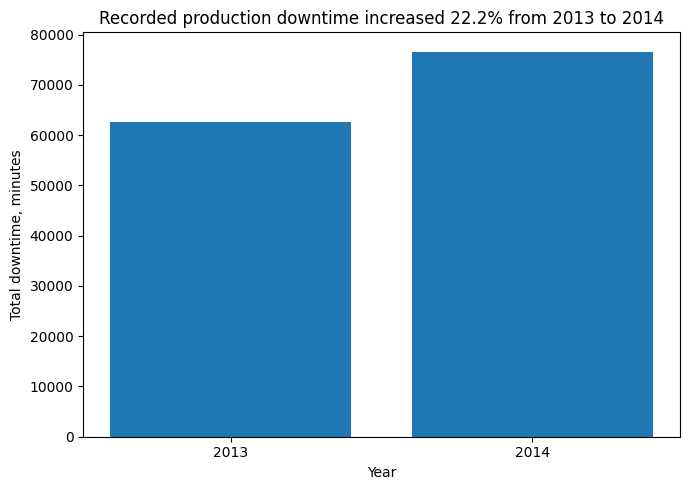

In [ ]:
plt.figure(figsize=(7, 5))

plt.bar(
    year_summary["Year"].astype(str),
    year_summary["total_downtime"]
)

plt.title(
    f"Recorded production downtime increased {percent_change:.1f}% from 2013 to 2014"
)

plt.xlabel("Year")
plt.ylabel("Total downtime, minutes")

plt.tight_layout()

plt.savefig(
    output_dir
    / "01_total_downtime_by_year.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Top 5 vendors' share of 2014 downtime: 41.02%


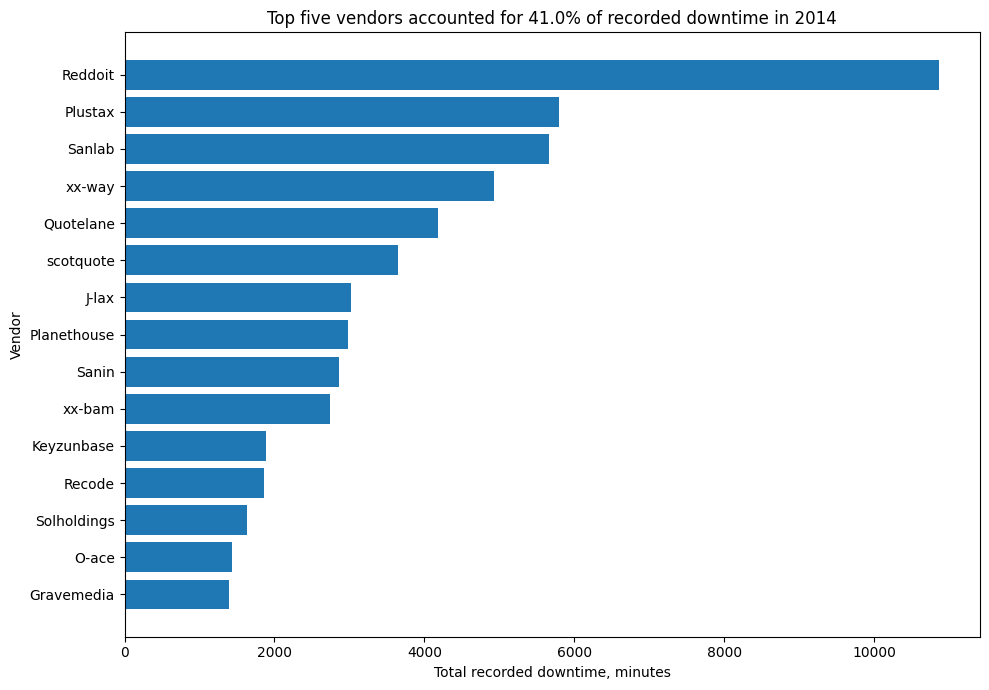

In [ ]:
top5_2014 = top_2014_all.head(5)

top5_share_2014 = (
    top5_2014["Downtime_min"].sum()
    / downtime_2014
    * 100
)

print(
    "Top 5 vendors' share of 2014 downtime:",
    f"{top5_share_2014:.2f}%"
)

chart_data = (
    top_2014_all
    .sort_values("Downtime_min")
)

plt.figure(figsize=(10, 7))

plt.barh(
    chart_data["Vendor"],
    chart_data["Downtime_min"]
)

plt.title(
    f"Top five vendors accounted for {top5_share_2014:.1f}% of recorded downtime in 2014"
)

plt.xlabel("Total recorded downtime, minutes")
plt.ylabel("Vendor")

plt.tight_layout()

plt.savefig(
    output_dir
    / "02_top_vendors_2014.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

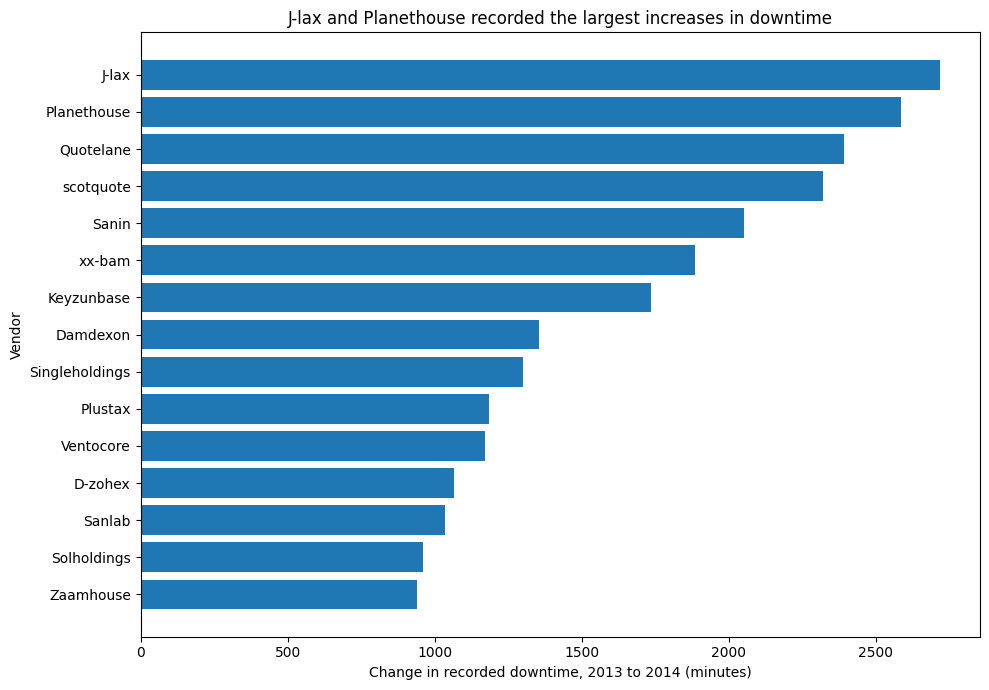

In [ ]:
chart_data = (
    top_increase_common
    .sort_values("Absolute_change")
)

plt.figure(figsize=(10, 7))

plt.barh(
    chart_data["Vendor"],
    chart_data["Absolute_change"]
)

plt.title(
    "J-lax and Planethouse recorded the largest increases in downtime"
)

plt.xlabel(
    "Change in recorded downtime, 2013 to 2014 (minutes)"
)

plt.ylabel("Vendor")

plt.tight_layout()

plt.savefig(
    output_dir
    / "03_largest_vendor_increases.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

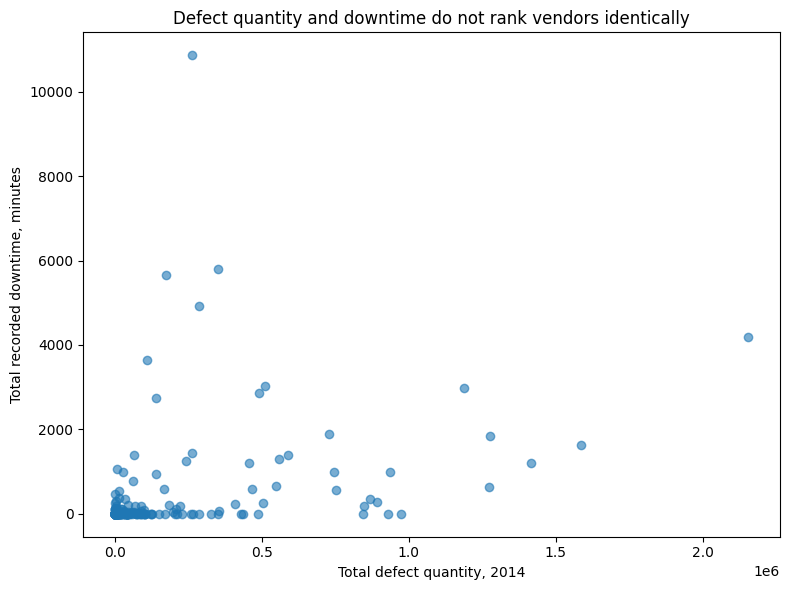

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    vendor_metrics_2014["total_defects"],
    vendor_metrics_2014["total_downtime"],
    alpha=0.6
)

plt.xlabel("Total defect quantity, 2014")
plt.ylabel("Total recorded downtime, minutes")

plt.title(
    "Defect quantity and downtime do not rank vendors identically"
)

plt.tight_layout()

plt.savefig(
    output_dir
    / "04_defects_vs_downtime_2014.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
year_summary.to_csv(
    output_dir / "year_summary.csv",
    index=False
)

comparison_summary.to_csv(
    output_dir / "overall_vs_common_vendors.csv",
    index=False
)

vendor_compare.to_csv(
    output_dir / "all_vendor_comparison.csv",
    index=False
)

common_compare.to_csv(
    output_dir / "common_vendor_comparison.csv",
    index=False
)

top_2014_all.to_csv(
    output_dir / "top_vendors_2014.csv",
    index=False
)

top_current_common.to_csv(
    output_dir / "top_current_common_vendors.csv",
    index=False
)

top_increase_common.to_csv(
    output_dir / "largest_vendor_increases.csv",
    index=False
)

top_decrease_common.to_csv(
    output_dir / "largest_vendor_improvements.csv",
    index=False
)

plant_summary.to_csv(
    output_dir / "plant_summary.csv",
    index=False
)

material_summary.to_csv(
    output_dir / "material_summary.csv",
    index=False
)

defect_type_summary.to_csv(
    output_dir / "defect_type_summary.csv",
    index=False
)

defect_type_compare.to_csv(
    output_dir / "defect_type_change.csv",
    index=False
)

ranking_comparison.to_csv(
    output_dir / "outlier_sensitivity.csv",
    index=False
)

vendor_metrics_2014.to_csv(
    output_dir / "downtime_vs_defect_ranking_2014.csv",
    index=False
)

cleaning_log.to_csv(
    output_dir / "cleaning_log.csv",
    index=False
)

data_dictionary.to_csv(
    output_dir / "data_dictionary.csv",
    index=False
)

print("CSV files exported successfully.")

CSV files exported successfully.


In [ ]:
output_excel = (
    output_dir /
    "supplier_quality_D4_analysis.xlsx"
)

with pd.ExcelWriter(
    output_excel,
    engine="openpyxl"
) as writer:

    year_summary.to_excel(
        writer,
        sheet_name="Year Summary",
        index=False
    )

    comparison_summary.to_excel(
        writer,
        sheet_name="Overall vs Common",
        index=False
    )

    top_2014_all.to_excel(
        writer,
        sheet_name="Top Vendors 2014",
        index=False
    )

    top_current_common.to_excel(
        writer,
        sheet_name="Current Common",
        index=False
    )

    top_increase_common.to_excel(
        writer,
        sheet_name="Largest Increase",
        index=False
    )

    top_decrease_common.to_excel(
        writer,
        sheet_name="Largest Improvement",
        index=False
    )

    common_compare.to_excel(
        writer,
        sheet_name="Common Vendors",
        index=False
    )

    plant_summary.to_excel(
        writer,
        sheet_name="Plant",
        index=False
    )

    material_summary.to_excel(
        writer,
        sheet_name="Material",
        index=False
    )

    defect_type_compare.to_excel(
        writer,
        sheet_name="Defect Type Change",
        index=False
    )

    ranking_comparison.to_excel(
        writer,
        sheet_name="Sensitivity Outlier",
        index=False
    )

    vendor_metrics_2014.to_excel(
        writer,
        sheet_name="Defect vs Downtime",
        index=False
    )

    cleaning_log.to_excel(
        writer,
        sheet_name="Cleaning Log",
        index=False
    )

    data_dictionary.to_excel(
        writer,
        sheet_name="Data Dictionary",
        index=False
    )

print("Saved:", output_excel)

Saved: /content/output/supplier_quality_D4_analysis.xlsx


In [ ]:
print("=" * 65)
print("D4 MAIN RESULTS")
print("=" * 65)

print(f"Observations: {len(df):,}")
print(f"Unique vendors: {df['Vendor'].nunique():,}")
print(f"Plants: {df['Plant'].nunique():,}")

print("\nOVERALL")
print(
    f"2013 downtime: "
    f"{downtime_2013:,.0f} min"
)

print(
    f"2014 downtime: "
    f"{downtime_2014:,.0f} min"
)

print(
    f"Overall change: "
    f"{absolute_change:,.0f} min "
    f"({percent_change:.2f}%)"
)

print("\nVENDOR COVERAGE")
print(f"2013 vendors: {len(vendors_2013)}")
print(f"2014 vendors: {len(vendors_2014)}")
print(f"Common vendors: {len(common_vendors)}")
print(f"2013 only: {len(only_2013)}")
print(f"2014 only: {len(only_2014)}")

print("\nLIKE-FOR-LIKE COMMON VENDORS")
print(
    f"2013 downtime: "
    f"{common_2013:,.0f} min"
)

print(
    f"2014 downtime: "
    f"{common_2014:,.0f} min"
)

print(
    f"Change: "
    f"{common_absolute_change:,.0f} min "
    f"({common_pct_change:.2f}%)"
)

print("\nTOP 2014 VENDOR")

print(
    top_2014_all.iloc[0]["Vendor"],
    "-",
    f'{top_2014_all.iloc[0]["Downtime_min"]:,.0f} min'
)

print("\nLARGEST DETERIORATION")

print(
    top_increase_common.iloc[0]["Vendor"],
    "-",
    f'{top_increase_common.iloc[0]["Absolute_change"]:,.0f} min'
)

print("\nTOP FIVE SHARE OF 2014 DOWNTIME")

print(
    f"{top5_share_2014:.2f}%"
)

print("\nP99 SENSITIVITY")
print(
    f"P99 threshold: {p99:,.0f} min"
)

print(
    f"Records above P99: "
    f"{len(extreme_records):,}"
)

D4 MAIN RESULTS
Observations: 6,145
Unique vendors: 318
Plants: 24

OVERALL
2013 downtime: 62,681 min
2014 downtime: 76,607 min
Overall change: 13,926 min (22.22%)

VENDOR COVERAGE
2013 vendors: 162
2014 vendors: 287
Common vendors: 131
2013 only: 31
2014 only: 156

LIKE-FOR-LIKE COMMON VENDORS
2013 downtime: 61,446 min
2014 downtime: 69,939 min
Change: 8,493 min (13.82%)

TOP 2014 VENDOR
Reddoit - 10,866 min

LARGEST DETERIORATION
J-lax - 2,718 min

TOP FIVE SHARE OF 2014 DOWNTIME
41.02%

P99 SENSITIVITY
P99 threshold: 360 min
Records above P99: 59
